# Logistic Regression

**Objective:** predict `is_canceled` (1 = cancelled) using the team's approved booking features.

This is the presentation notebook for the reusable implementation in `src/logistic_regression.py`. It covers the project handover, preprocessing, leakage safeguards, grouped cross-validation, class weighting, evaluation and saved model. Other members' work remains unchanged.

Run all cells in order. Saved results are displayed by default; set `RUN_TRAINING = True` to retrain. If no results exist, training runs automatically. Use Python 3.11 and `requirements-logistic.txt`; scikit-learn 1.6.1 matches the shared preprocessing asset.

## 1. Locate the project

Local Jupyter/VS Code discovers the project from the current directory. In Colab, use the team's Drive folder or set the `HOTEL_BOOKING_ROOT` environment variable. Install the requirements before running, then restart the kernel if versions changed.

In [1]:
from pathlib import Path
import os
import sys
import json
import pandas as pd
import numpy as np
import joblib
from IPython.display import display, Markdown, Image

project_override = os.environ.get('HOTEL_BOOKING_ROOT')
ROOT = Path(project_override).expanduser().resolve() if project_override else next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'src/logistic_regression.py').is_file()), None)
if ROOT is None:
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError('Open inside the project or set HOTEL_BOOKING_ROOT.') from None
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/hotel-booking-cancellation')
sys.path.insert(0, str(ROOT))
from src.logistic_regression import (run, load_data, build_pipeline, purge_overlap,
                                     feature_keys, make_folds)
REPORT = ROOT / 'reports/logistic_regression'
RESULTS = ROOT / 'results/logistic_regression'
RUN_TRAINING = False
print('Project:', ROOT)


Project: /Users/sbwaxan/Downloads/hotel-booking-cancellation 5


## 2. Understand the actual handover

The raw data has 119,390 bookings and 32 columns. Cleaning produces 87,222 rows with no remaining missing cells. Feature engineering excludes five outcome/timing-sensitive fields and adds `total_stay`, `total_guests`, and `is_family`. The result has 28 predictors plus the target.

Notebook 04 creates the shared 80/20 stratified split (seed 42) and unfitted preprocessor. Random Forest, Decision Tree and XGBoost already use those assets. The detailed file-by-file review and contribution boundaries are in `reports/logistic_regression/README.md`.

The loader verifies all feature groups, binary targets, prohibited fields and exact reproduction of the shared split from the approved dataset. No columns are invented.

In [2]:
config, shared_X, X_test, shared_y, y_test = load_data(ROOT)
profile = pd.DataFrame({
    'dtype': shared_X.dtypes.astype(str),
    'missing_train': shared_X.isna().sum(),
    'unique_train': shared_X.nunique(),
})
display(profile)
display(shared_y.value_counts().sort_index().rename('count').to_frame().assign(
    percentage=lambda table: 100 * table['count'] / len(shared_y)))
print('Shared train:', shared_X.shape, '| Shared test:', X_test.shape)


,dtype,missing_train,unique_train
hotel,object,0,2
lead_time,int64,0,473
arrival_date_year,int64,0,3
arrival_date_month,object,0,12
arrival_date_week_number,int64,0,53
arrival_date_day_of_month,int64,0,31
stays_in_weekend_nights,int64,0,16
stays_in_week_nights,int64,0,32
adults,int64,0,13
children,float64,0,5


,count,percentage
is_canceled,,
0,50570,72.473738
1,19207,27.526262


Shared train: (69777, 28) | Shared test: (17445, 28)


## 3. Prevent predictor overlap

After columns are excluded, distinct original records can have identical approved predictors. There are 721 shared test rows whose predictors match training rows. Keep the shared holdout and conservatively exclude every matching training row **only within this LR workflow**. This uses predictor equality, never the test labels or model performance; it removes 933 training rows, leaving 68,844.

For cross-validation, identical predictor rows (even with conflicting labels) stay together using `StratifiedGroupKFold`. There is no customer/booking identifier, so predictor equality is a proxy, not proof of a duplicate booking. The train sample and CV protocol now differ from teammates', which must accompany comparisons.

In [3]:
X_train, y_train, keep = purge_overlap(shared_X, X_test, shared_y)
folds = make_folds(X_train, y_train)
assert not feature_keys(X_train).isin(feature_keys(X_test)).any()
display(pd.DataFrame([
    {'split': 'Shared training', 'rows': len(shared_X), 'cancelled_pct': shared_y.mean()*100},
    {'split': 'Effective LR training', 'rows': len(X_train), 'cancelled_pct': y_train.mean()*100},
    {'split': 'Shared test', 'rows': len(X_test), 'cancelled_pct': y_test.mean()*100},
]))
display(pd.DataFrame([
    {'fold': i, 'training_rows': len(tr), 'validation_rows': len(va),
     'validation_cancelled_pct': y_train.iloc[va].mean()*100}
    for i, (tr, va) in enumerate(folds)
]))


,split,rows,cancelled_pct
0,Shared training,69777,27.526262
1,Effective LR training,68844,27.559410
2,Shared test,17445,27.526512


,fold,training_rows,validation_rows,validation_cancelled_pct
0,0,55059,13785,28.487486
1,1,55039,13805,27.678377
2,2,55086,13758,27.474924
3,3,55090,13754,26.988512
4,4,55102,13742,27.164896


## 4. Build the scikit-learn pipeline

- **16 numerical features:** median imputation → StandardScaler.
- **2 binary features:** most-frequent imputation (a missing-value safeguard), otherwise unchanged 0/1.
- **10 categorical features:** most-frequent imputation → one-hot encoding. Agent IDs remain text. Categories occurring fewer than 50 times in each training fold are grouped; unknown categories map to an infrequent bucket if present, otherwise all zeros for that field.

Clone the shared preprocessor. Sparse storage changes representation, not numeric results; a test verifies equivalence with the team's dense output. All fitted transformations remain inside CV.

Retain all approved features; L2 regularization controls correlated inputs. Dropping features based on full-sample target correlations would contaminate validation. Aggregate/source redundancy means coefficient interpretation needs care.

In [4]:
pipeline = build_pipeline(ROOT, config)
# The displayed estimator is NEW and UNFITTED; GridSearchCV clones it per fold.
display(pipeline)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lead_time',
                                                   'arrival_date_year',
                                                   'arrival_date_week_number',
                                                   'arrival_date_day_of_month',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                                                   'babies',
                                                   'pr...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=50))]),
                                                  ['hotel',
                                                   'arrival_date_month', 'meal',
                                                   'country', 'market_segment',
                                                   'distribution_channel',
                                                   'reserved_room_type',
                                                   'deposit_type',
                                                   'customer_type',
                                                   'agent'])])),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])

## 5. Tune regularization and imbalance handling

Logistic Regression models log-odds as a linear combination of transformed inputs. Lower `C` applies stronger L2 regularization.

Search `C = [0.01, 0.1, 1, 10]` and `class_weight = [None, 'balanced']`: 8 candidates × 5 grouped folds. The unweighted `C=1` candidate is the baseline LR. Balanced class weights use each fold's labels, addressing the approximately 27.5% cancellation class without synthetic observations.

Select by cancellation **F1** at a fixed 0.5 threshold; record all five requested metrics. Solver is `lbfgs`, max_iter=2000, tol=1e-4, seed=42. Convergence warnings fail visibly. No test-driven threshold tuning. The winning CV score is selection evidence, not an unbiased nested-CV estimate.

The call below performs the complete workflow and saves the fitted pipeline. Set `RUN_TRAINING=True` for a fresh run.

Displaying saved measured results. Set RUN_TRAINING=True to retrain.
Selected parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Convergence iterations: [73]


,param_model__C,param_model__class_weight,rank_test_f1,mean_train_f1,mean_test_f1,std_test_f1,mean_test_precision,mean_test_recall,mean_test_roc_auc
3,0.10,balanced,1,0.6565,0.6548,0.0060,0.5498,0.8095,0.8533
7,10.00,balanced,2,0.6570,0.6537,0.0065,0.5494,0.8071,0.8532
5,1.00,balanced,3,0.6570,0.6536,0.0062,0.5493,0.8070,0.8532
1,0.01,balanced,4,0.6521,0.6500,0.0071,0.5450,0.8054,0.8511
6,10.00,NaN,5,0.5812,0.5775,0.0062,0.6719,0.5066,0.8524
4,1.00,NaN,6,0.5802,0.5771,0.0064,0.6719,0.5060,0.8524
2,0.10,NaN,7,0.5778,0.5745,0.0067,0.6742,0.5008,0.8524
0,0.01,NaN,8,0.5614,0.5606,0.0043,0.6822,0.4761,0.8496


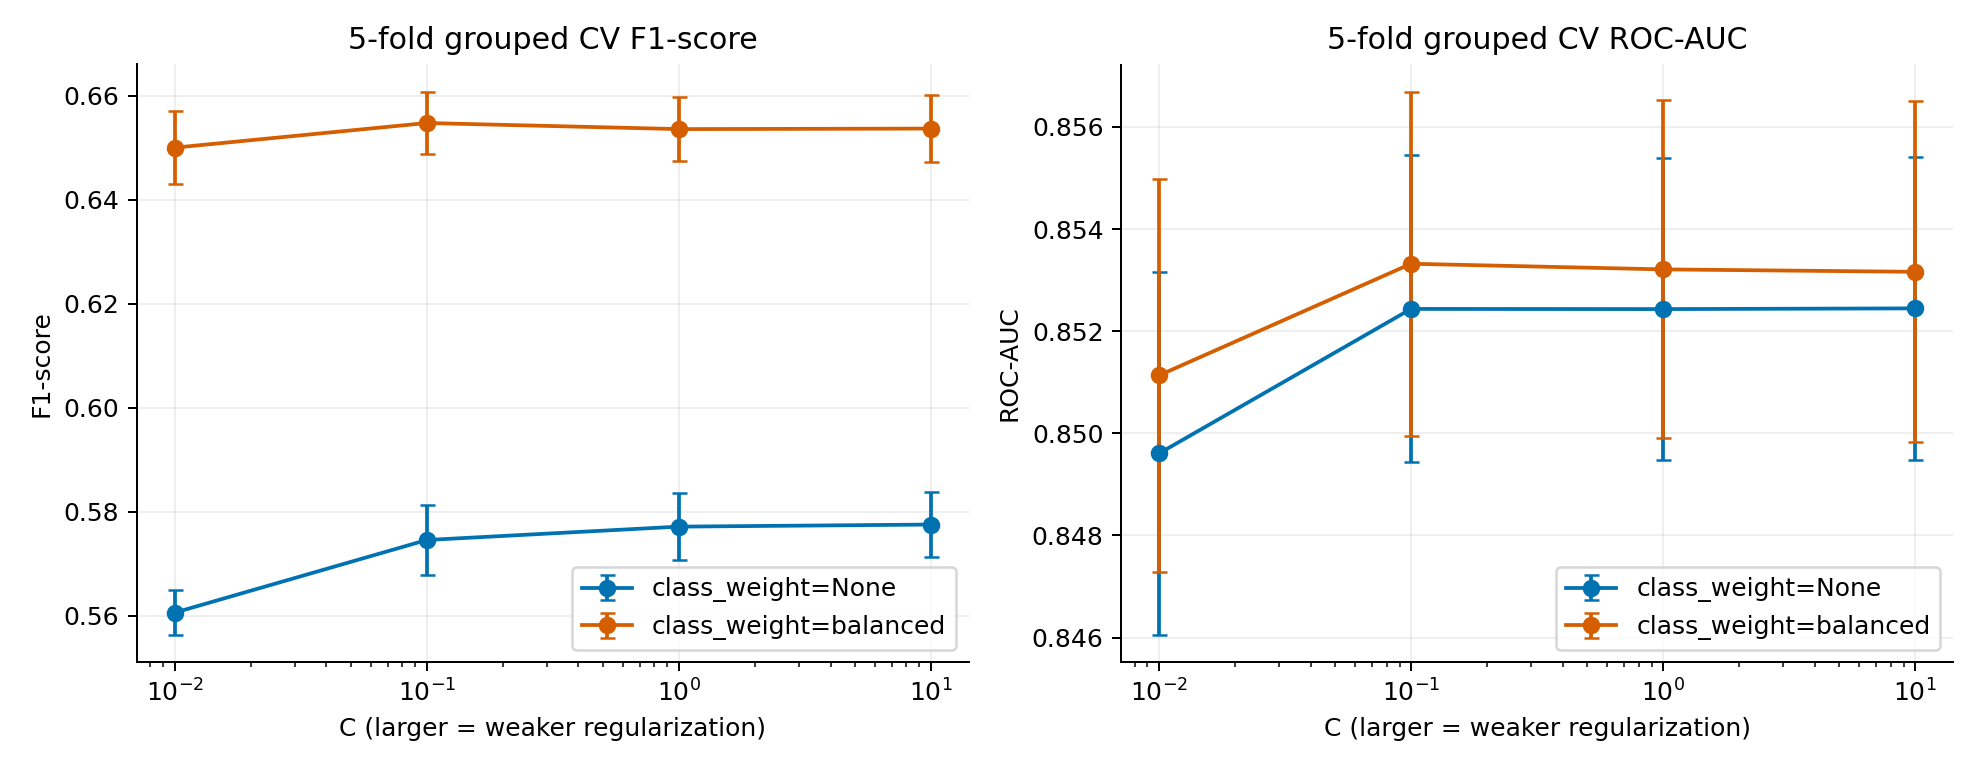

In [5]:
if RUN_TRAINING or not (RESULTS / 'metrics.json').exists():
    summary = run(ROOT)
else:
    summary = json.loads((RESULTS / 'metrics.json').read_text())
    print('Displaying saved measured results. Set RUN_TRAINING=True to retrain.')
    # Do not silently display stale results for changed shared inputs.
    import hashlib
    audit = json.loads((REPORT / 'data_audit.json').read_text())
    for name, expected_hash in audit['input_sha256'].items():
        assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == expected_hash, name
print('Selected parameters:', summary['best_params'])
print('Convergence iterations:', summary['n_iter'])
cv_results = pd.read_csv(RESULTS / 'cv_results.csv')
columns = ['param_model__C', 'param_model__class_weight', 'rank_test_f1',
           'mean_train_f1', 'mean_test_f1', 'std_test_f1',
           'mean_test_precision', 'mean_test_recall', 'mean_test_roc_auc']
display(cv_results[columns].sort_values('rank_test_f1').round(4))
display(Image(filename=str(RESULTS / 'cv_tuning.png')))


## 6. Train vs CV vs test performance

Accuracy alone can hide poor minority-class performance. The majority-class dummy predicts every booking as not cancelled: 72.47% test accuracy but zero cancellation recall/F1 and ROC-AUC 0.5. The winning LR model detects more cancellations, at the cost of false alarms.

Use the gaps below to assess observed overfitting. Similar train/test scores do not prove the model is sufficiently flexible: a linear log-odds model can still miss interactions. CV standard deviations describe fold variation, not confidence intervals.

,Accuracy,Precision,Recall,F1-score,ROC-AUC
split,,,,,
Training,0.7665,0.5519,0.8125,0.6573,0.8554
CV validation (selection),0.7648,0.5498,0.8095,0.6548,0.8533
Test,0.7678,0.5529,0.8178,0.6598,0.8601


,CV standard deviation
Accuracy,0.0032
Precision,0.0091
Recall,0.0039
F1-score,0.0060
ROC-AUC,0.0034


,Train minus test
Accuracy,-0.0014
Precision,-0.0011
Recall,-0.0053
F1-score,-0.0025
ROC-AUC,-0.0047


,Majority dummy test
Accuracy,0.7247
Precision,0.0000
Recall,0.0000
F1-score,0.0000
ROC-AUC,0.5000


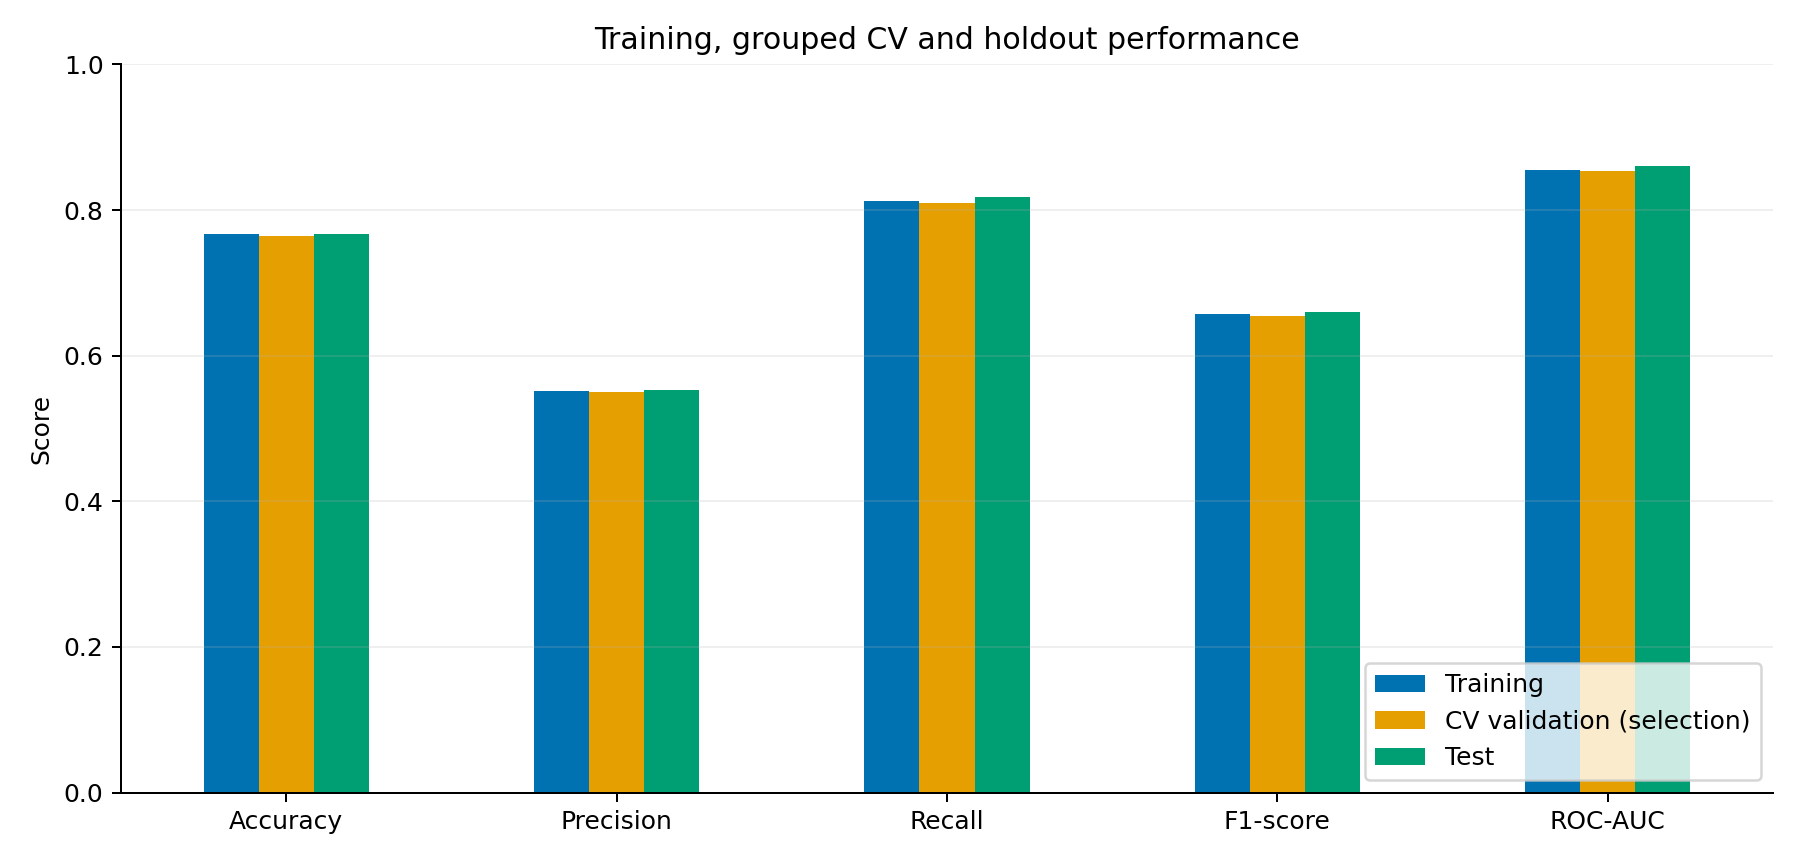

In [6]:
metrics = pd.read_csv(RESULTS / 'metrics.csv', index_col='split')
display(metrics.round(4))
display(pd.Series(summary['cv_std'], name='CV standard deviation').to_frame().round(4))
display(pd.Series(summary['train_minus_test'], name='Train minus test').to_frame().round(4))
display(pd.Series(summary['dummy_test_metrics'], name='Majority dummy test').to_frame().round(4))
display(Image(filename=str(RESULTS / 'performance_comparison.png')))


## 7. Classification report, confusion matrix and ROC curve

Positive class = cancelled. False negatives are missed cancellations; false positives are bookings flagged as cancelled that did not cancel. ROC-AUC uses probabilities over thresholds, while the confusion matrix and class metrics use the fixed 0.5 threshold.

               precision    recall  f1-score   support

Not cancelled     0.9154    0.7489    0.8238     12643
    Cancelled     0.5529    0.8178    0.6598      4802

     accuracy                         0.7678     17445
    macro avg     0.7342    0.7833    0.7418     17445
 weighted avg     0.8156    0.7678    0.7787     17445



,Bookings
tn,9468
fp,3175
fn,875
tp,3927


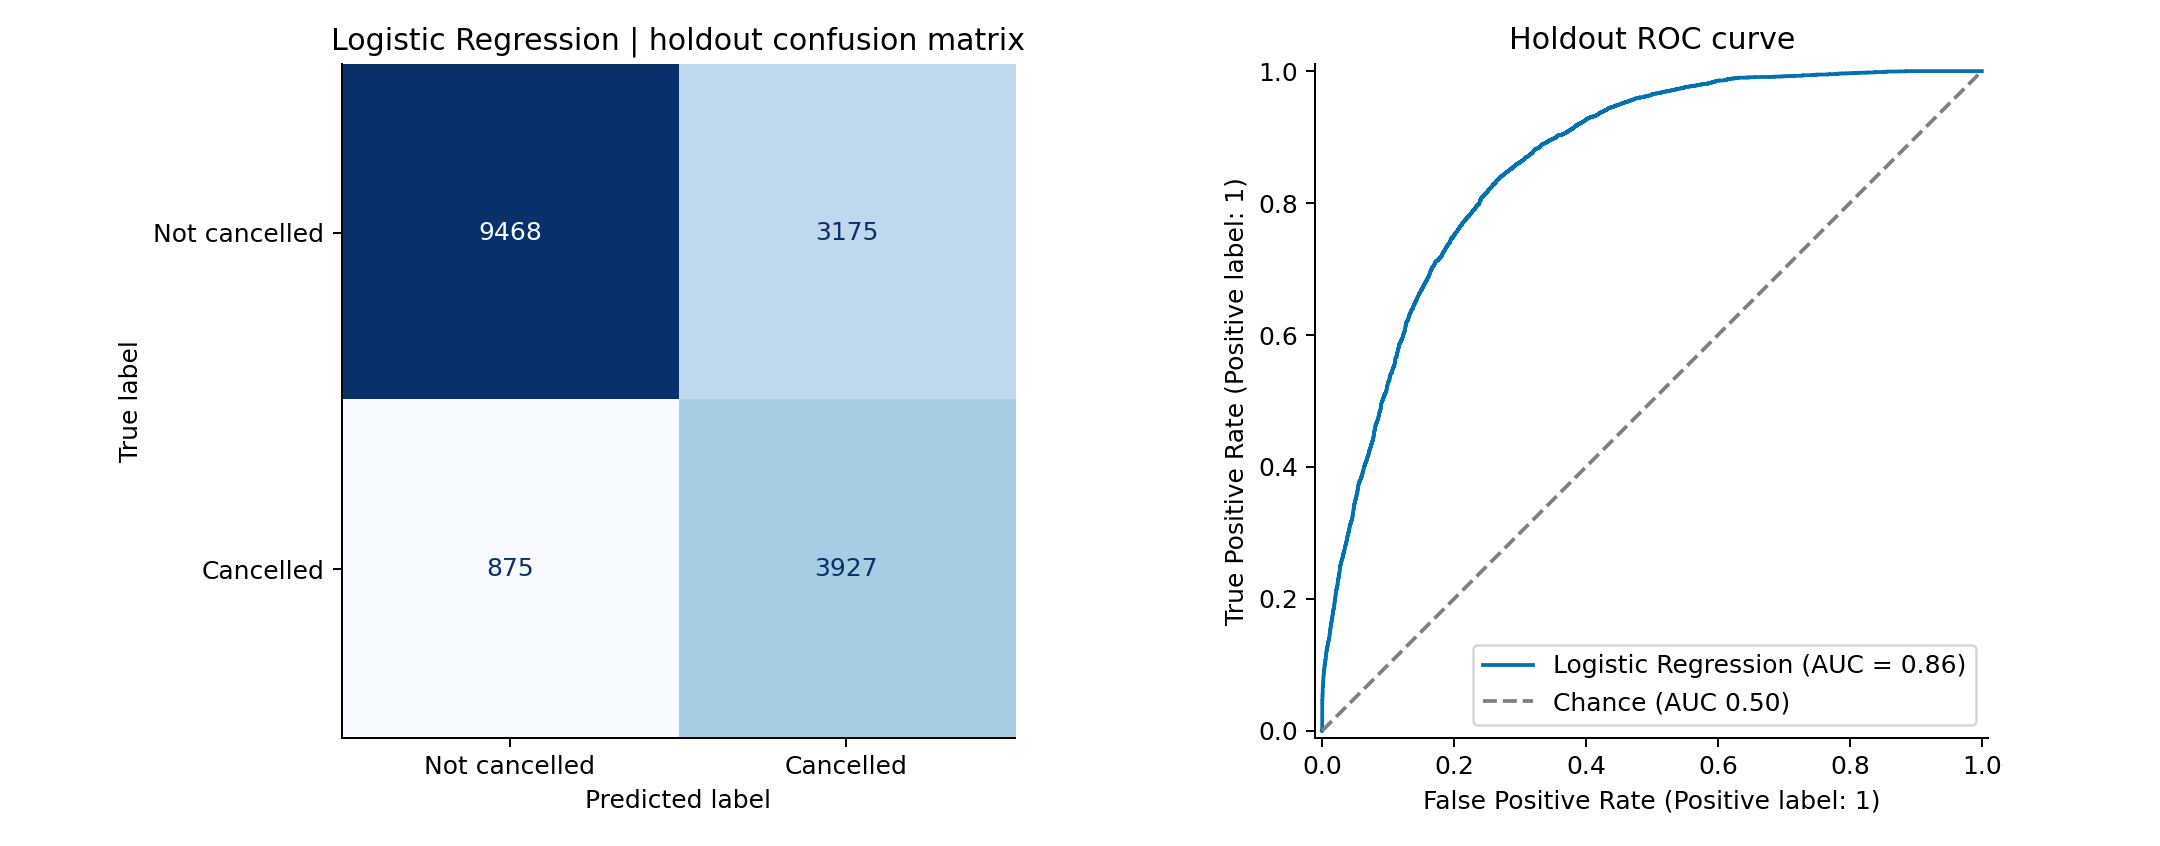

In [7]:
print((REPORT / 'classification_report.txt').read_text())
display(pd.Series(summary['confusion_matrix'], name='Bookings').to_frame())
display(Image(filename=str(RESULTS / 'confusion_matrix_roc.png')))


## 8. Interpret coefficients carefully

A positive coefficient raises the model's log-odds of cancellation, holding other encoded inputs fixed. Numerical effects are per training standard deviation; categorical effects are one-hot contributions. Their magnitudes are not directly interchangeable measures of business importance. L2 regularization and redundant variables distribute effects across predictors; these are not causal effects, p-values, or reference-category odds ratios.

,feature,coefficient
12,num__required_car_parking_spaces,-2.004632
148,cat__agent_240,1.987211
185,cat__agent_9,1.925491
73,cat__country_PRT,1.857405
105,cat__deposit_type_No Deposit,-1.311970
106,cat__deposit_type_Non Refund,1.235003
16,bin__is_repeated_guest,-1.178244
36,cat__country_AGO,1.160182
150,cat__agent_242,1.037019
128,cat__agent_152,-0.949442


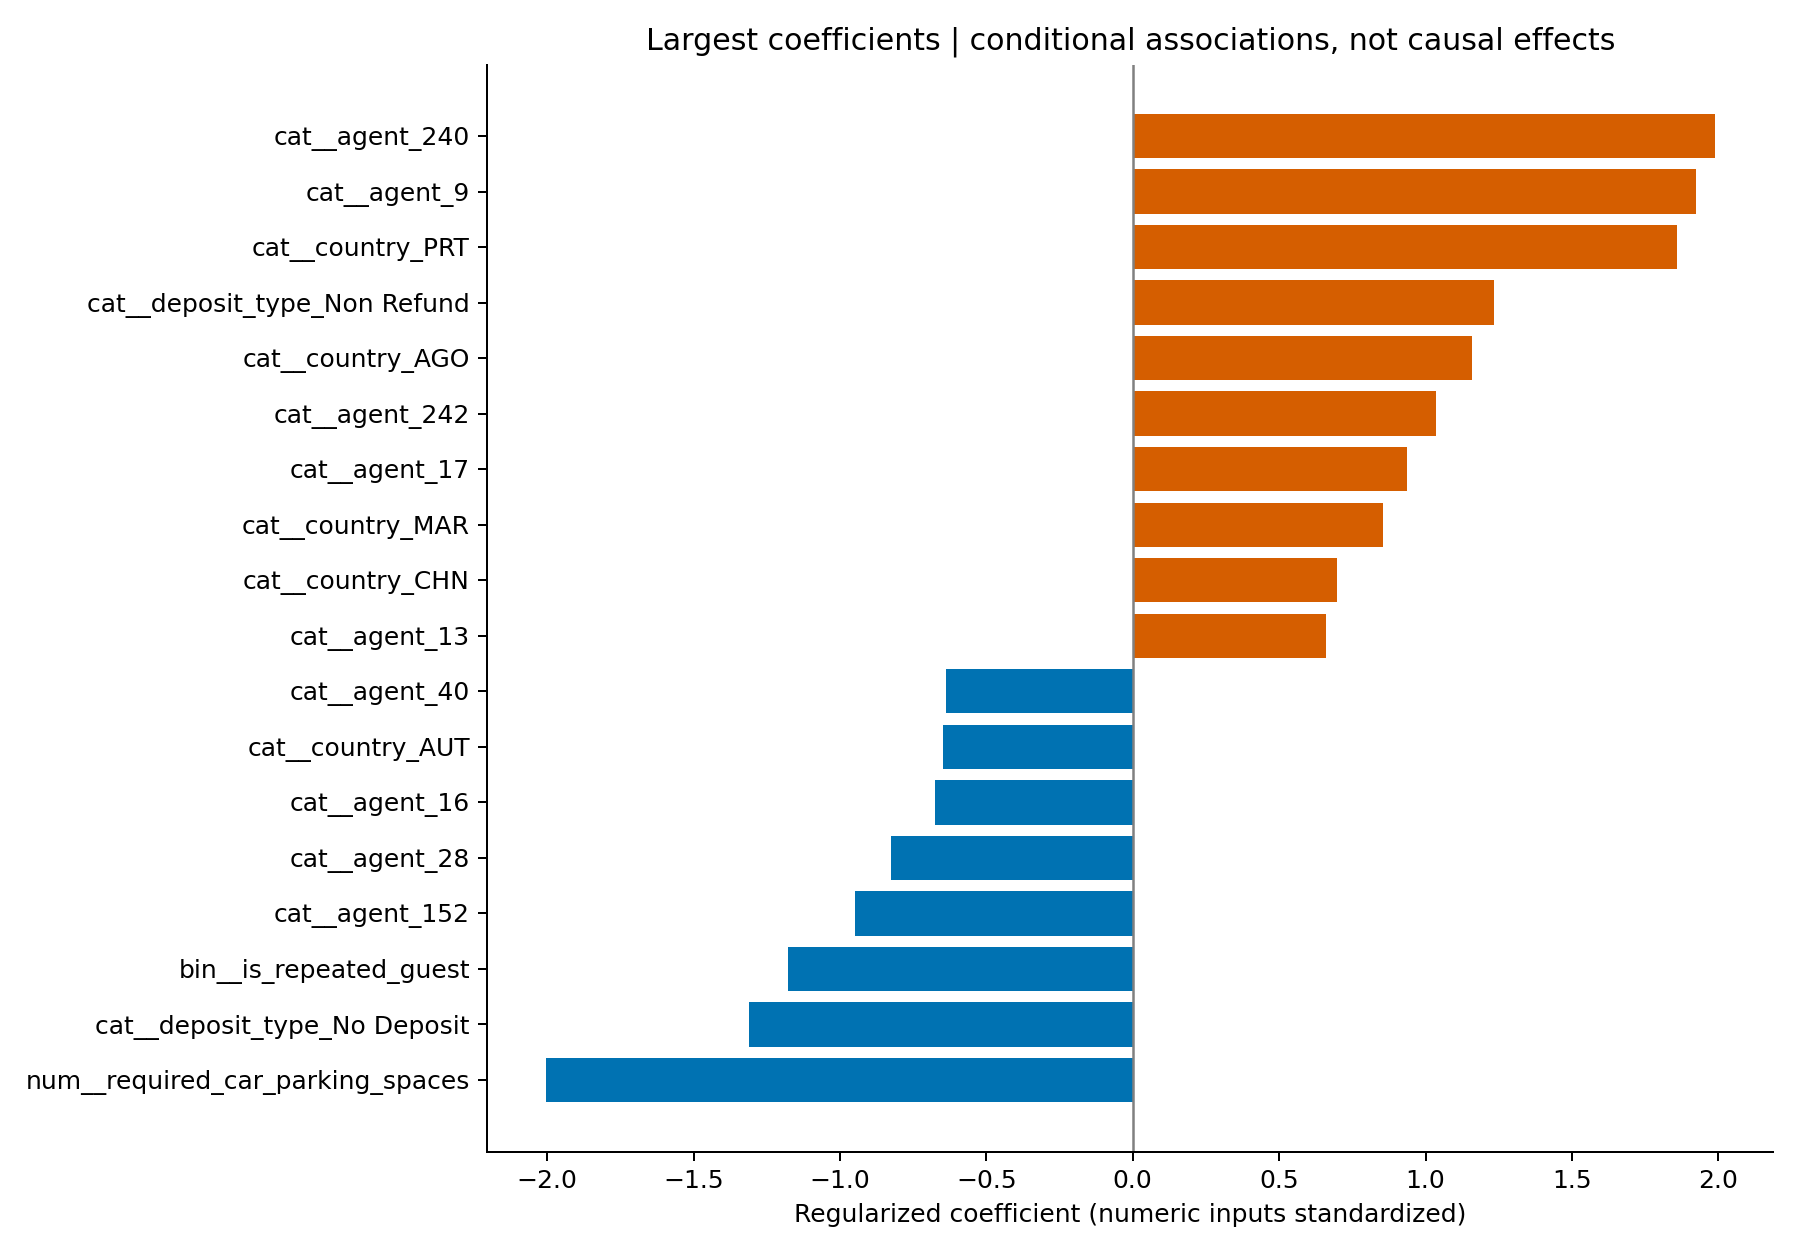

In [8]:
coefficients = pd.read_csv(REPORT / 'coefficients.csv')
display(coefficients.reindex(coefficients.coefficient.abs().nlargest(15).index))
display(Image(filename=str(RESULTS / 'coefficients.png')))


## 9. Reload and use the saved model

`pipeline.joblib` contains both fitted preprocessing and classifier. Supply the 28 approved features, including the team's engineered columns, with agent as text. The saved pipeline does not perform the earlier raw-data cleaning stage.

In [9]:
model = joblib.load(ROOT / 'models/logistic_regression/pipeline.joblib')
sample = X_test.iloc[:5]
probability = model.predict_proba(sample)[:, 1]
saved = pd.read_csv(RESULTS / 'test_predictions.csv')
np.testing.assert_allclose(probability, saved.cancellation_probability.iloc[:5], rtol=1e-10)
display(pd.DataFrame({'probability_cancelled': probability,
                      'prediction': (probability >= summary['threshold']).astype(int),
                      'actual': y_test.iloc[:5].to_numpy()}))
print('Reloaded predictions match saved results.')


,probability_cancelled,prediction,actual
0,0.501220,1,0
1,0.106813,0,1
2,0.793317,1,0
3,0.276128,0,0
4,0.139771,0,0


Reloaded predictions match saved results.


## 10. Viva summary and limitations

**Logistic Regression scope:** Logistic Regression pipeline adaptation, overlap audit and local exclusions, grouped cross-validation, class-weight and regularization search, train/test evaluation, diagnostic plots, complete model persistence and reproducibility tests. Existing data cleaning, approved feature engineering and base preprocessing remain credited to teammates.

**Limitations:** upstream EDA already used the full historical sample; this is not a sealed external test. CSVs do not verify booking-time snapshots of ADR, deposits, requests, parking or history cutoffs. Random historical splitting cannot establish future-period or unseen-hotel performance. Identical-predictor grouping cannot identify all repeated customers. Balanced-weight probabilities should not be assumed calibrated; calibration or business-cost threshold selection would require training-only validation and a separate evaluation design.

Read the generated result summary below and the detailed README for commands and output paths. There is no automatic claim of superiority over other models because their training/CV protocols differ.

In [10]:
display(Markdown((REPORT / 'results_summary.md').read_text()))


# Logistic Regression — measured results

Trained on 68,844 bookings after excluding 933 overlapping training rows; evaluated on all 17,445 shared test bookings.

Best settings: `{'model__C': 0.1, 'model__class_weight': 'balanced'}`; L2, lbfgs, threshold 0.5, seed 42. Five-fold grouped CV selected by cancellation F1: 0.6548.

| Metric | Training | CV validation* | Test |
|---|---:|---:|---:|
| Accuracy | 0.7665 | 0.7648 | 0.7678 |
| Precision | 0.5519 | 0.5498 | 0.5529 |
| Recall | 0.8125 | 0.8095 | 0.8178 |
| F1-score | 0.6573 | 0.6548 | 0.6598 |
| ROC-AUC | 0.8554 | 0.8533 | 0.8601 |

*Selection CV, not nested CV. Standard deviations and all candidates are in the results files.

Majority baseline test accuracy: 0.7247; F1: 0.0000; ROC-AUC: 0.5000.

Confusion matrix: TN=9,468, FP=3,175, FN=875, TP=3,927.

Train–test F1 gap: -0.0025; ROC-AUC gap: -0.0047. Small gaps suggest limited observed overfitting, but do not establish that a linear model captures all useful structure. The cancellation recall and false-negative count quantify remaining errors.

## Limitations

- Same CV folds selected the winner: winning CV score is not an unbiased nested-CV estimate.
- Holdout was already explored upstream; not a prospectively untouched external dataset.
- No booking/customer identifiers: equal predictors are a conservative overlap proxy, not proven duplicate bookings.
- Booking-time availability of ADR/deposit/requests/parking and historical cutoffs is assumed upstream, not verified by these CSVs.
- Random historical holdout does not demonstrate future-period or new-hotel generalization.
- Correlated aggregate/source features and full one-hot blocks make individual coefficients non-causal and non-unique without regularization.
